<div style="background:linear-gradient(90deg,#1f5fa8,#6a3ea1); padding:18px 22px; border-radius:8px; color:white;">
<h1 style="color:white; margin:0;">Section 3 &mdash; Numerical Simulations and Visualisation</h1>
<p style="margin:6px 0 0 0;">MAC F314 Mathematical Modelling &middot; Canadian lynx&ndash;snowshoe hare &middot; Owner: Rishi</p>
</div>

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">What this section does</b>

Section 2 (Joel) proves that the coexistence equilibrium $E^*$ of the Rosenzweig&ndash;MacArthur model loses stability at

$$K_H = b + 2H^*, \qquad H^* = \frac{mb}{ea-m},$$

where a complex pair of eigenvalues crosses the imaginary axis (Hopf bifurcation). Linear analysis is **local**: it describes
behaviour near $E^*$ at a single parameter value. This section tests the analytic claims numerically and **measures what
linearisation cannot give**: global behaviour, cycle size, period, predator lag and the shape of the bifurcation.

| Output | Question it answers |
|---|---|
| Fig. 1 | Is the solver accurate enough to trust? |
| Regime table | Do simulations reproduce Joel's validation targets A&ndash;F? |
| Fig. 2 | Does stability switch where the theory says? |
| Fig. 3 | Is the cycle a *stable* limit cycle (unlike Lotka&ndash;Volterra)? |
| Fig. 4 | Do the eigenvalues cross the imaginary axis exactly at $K_H$? |
| Fig. 5 | Is the cycle born at $K_H$ with zero size? (bifurcation diagram) |
| Fig. 6 | Does it grow like $\sqrt{K-K_H}$ with period $\to T_0$? (supercritical Hopf) |

</div>

<div style="background:#f2ecfa; border-left:6px solid #6a3ea1; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#6a3ea1; font-size:1.1em;">Model, parameters and solver</b>

$$\frac{dH}{dt} = rH\left(1-\frac{H}{K}\right) - \frac{aH}{b+H}P, \qquad \frac{dP}{dt} = e\frac{aH}{b+H}P - mP$$

$H, P$: hare and lynx index (thousand pelts); $t$ in years. **Illustrative, not fitted** (Section 2, &sect;1.8):
$r=1.5,\ a=4,\ b=30,\ e=0.4,\ m=0.8$, so $ea = 2m$ and

$$H^* = 30,\quad K_H = 90,\quad \omega_0 = \sqrt{rmb/K_H} \approx 0.632,\quad T_0 = 2\pi/\omega_0 \approx 9.94 \text{ yr}.$$

**Solver:** `scipy.integrate.solve_ivp`, RK45 (Dormand&ndash;Prince). Each step evaluates the right-hand side seven times and
combines the slopes into a 4th- and a 5th-order estimate; their difference estimates the local error. Steps whose error exceeds
`rtol`$\cdot|y|$ + `atol` are rejected and shrunk, small errors let the next step grow.

**Two solver settings, two jobs.** Fitting and the 1900&ndash;1920 forecasts (Yash, Advay) use `model.solve`:
RK45, `rtol = 1e-8`, `atol = 1e-10`, `max_step = 0.1` years, identical for both fitting methods (`configs/historical.json`).
The long-run simulations here run for thousands of years and use tighter tolerances: RK45, `rtol = 1e-10`,
`atol = 1e-12`, no step cap (`simulation.integrate`). Both call the same `model.rhs`.
Illustrative runs start at $(20, 5)$ with a 3000-year burn-in (20,000 years within one unit of $K_H$, where the
equilibrium is a weak focus and transients decay very slowly).

All values above live in `configs/simulations.json`. All trajectories use the team's single right-hand side `model.rhs`; analytic targets come from Joel's `stability.py`.

</div>

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from lynx_hare.model import Parameters, rhs        # shared model (Arnav / group contract)
from lynx_hare import stability as st              # Joel's closed forms

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Implementation 1 &mdash; simulation layer (`src/lynx_hare/simulation.py`)</b>

Algorithms in this module:

- **`integrate`**: RK45 with the declared tolerances; fails loudly if the solver does.
- **`attractor_summary`**: integrate to $T_\text{burn} + T_\text{rec}$, **discard** $t < T_\text{burn}$, and on the recorded window
  return $\min/\max$ of $H$ and $P$. If $H$ still oscillates, the period is the mean gap between successive hare maxima, and
  the lag is the mean delay from each hare maximum to the next lynx maximum.
- **`bifurcation_sweep`**: `attractor_summary` over a grid of $K$; equal max and min means an equilibrium, a gap means a cycle.
- **`amplitude_law`**: half-amplitude $A$ and period at $K = K_H + \Delta K$; least-squares line through $(\ln\Delta K, \ln A)$.
- **Lotka&ndash;Volterra helpers** and a fixed-step **Euler** method for the solver-accuracy check.

</div>

In [2]:
# Generated from src/lynx_hare/simulation.py
"""Rishi's numerical simulations for the shared Rosenzweig-MacArthur model.

Every trajectory uses the team's single right-hand side, model.rhs, and every analytic
target comes from Joel's stability module, so this file adds numerics only:

* integrate          RK45 with the declared tolerances
* attractor_summary  post-transient min/max, period and predator lag
* bifurcation_sweep  numerical bifurcation diagram in K
* amplitude_law      cycle half-amplitude and period just above K_H
* linear_summary     sigma = K/K_H, eigenvalues, e-folding time and linear period at E*
* Lotka-Volterra helpers for the solver-accuracy check (conserved quantity)

Solver settings. Two RK45 settings are used in the project, for different jobs:
* fitting and 1900-1920 forecasts (Yash, Advay): model.solve, rtol 1e-8, atol 1e-10,
  max_step 0.1 years, from configs/historical.json;
* long-run simulations here (thousands of years, illustrative and fitted parameters):
  integrate(), rtol 1e-10, atol 1e-12, no max_step, from configs/simulations.json.

Parameters, solver settings and grids: configs/simulations.json.
Validation targets: docs/joel_stability_handoff.md.
"""
import json
from dataclasses import replace
from pathlib import Path

import numpy as np
from scipy.integrate import solve_ivp

from lynx_hare.model import Parameters, rhs
from lynx_hare import stability as st

CONFIG_PATH = ROOT / "configs" / "simulations.json"
CONFIG = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))

RTOL, ATOL = CONFIG["solver"]["rtol"], CONFIG["solver"]["atol"]   # declared tolerances
Y0 = tuple(CONFIG["initial_state"])                               # thousand pelts
T_BURN = CONFIG["burn_in_years"]
T_BURN_NEAR_HOPF = CONFIG["burn_in_years_near_hopf"]   # weak focus near K_H decays very slowly
NEAR_HOPF = CONFIG["near_hopf_window"]
ILLUSTRATIVE = dict(CONFIG["params"])                  # not fitted; H* = 30, K_H = 90
REGIMES = dict(CONFIG["regimes_K"])


def with_K(p: Parameters, K: float) -> Parameters:
    return replace(p, K=float(K))


def integrate(p, y0, t_span, t_eval=None, rtol=RTOL, atol=ATOL, fun=rhs):
    """RK45 (Dormand-Prince) solution of fun(t, y, p); raises if the solver fails."""
    sol = solve_ivp(fun, t_span, np.asarray(y0, dtype=float), args=(p,), method="RK45",
                    rtol=rtol, atol=atol, t_eval=t_eval)
    if not sol.success:
        raise RuntimeError(f"RK45 failed: {sol.message}")
    return sol


def local_maxima(x):
    """Indices i with x[i-1] < x[i] > x[i+1]."""
    x = np.asarray(x)
    return np.where((x[1:-1] > x[:-2]) & (x[1:-1] > x[2:]))[0] + 1


def default_burn_in(p: Parameters) -> float:
    if st.coexistence_feasible(p) and abs(p.K - st.hopf_threshold(p)) < NEAR_HOPF:
        return T_BURN_NEAR_HOPF
    return T_BURN


def attractor_summary(p, y0=Y0, t_burn=None, t_record=400.0, samples=40001, osc_tol=0.5):
    """Simulate past the transient and describe what the solution settles on.

    The first t_burn years are discarded. On the recorded window we report the range of
    H and P and, if H still oscillates by more than osc_tol, the mean period between hare
    peaks and the mean delay from each hare peak to the next lynx peak.
    """
    t_burn = default_burn_in(p) if t_burn is None else t_burn
    t = np.linspace(t_burn, t_burn + t_record, samples)
    H, P = integrate(p, y0, (0.0, t[-1]), t_eval=t).y
    out = dict(K=p.K, t_burn=t_burn, Hmin=H.min(), Hmax=H.max(), Pmin=P.min(), Pmax=P.max(),
               period=np.nan, lag=np.nan)
    hp, pp = local_maxima(H), local_maxima(P)
    if H.max() - H.min() > osc_tol and len(hp) > 2 and len(pp) > 2:
        out["period"] = float(np.mean(np.diff(t[hp])))
        lags = [t[pp][t[pp] > th][0] - th for th in t[hp] if np.any(t[pp] > th)]
        out["lag"] = float(np.mean(lags))
    return out


def regime_table(base=None, regimes=REGIMES, y0=Y0, t_burn=T_BURN):
    """Reproduce Joel's Table 2: eigenvalues plus simulated long-run behaviour.

    Uses the fixed 3000-year burn-in of Table 2 (so regime D keeps its expected
    slowly-decaying residual oscillation)."""
    base = base or Parameters(K=100.0, **ILLUSTRATIVE)
    rows = []
    for label, K in regimes.items():
        p = with_K(base, K)
        if st.coexistence_feasible(p):
            point = (st.coexistence_prey(p), st.coexistence_predator(p))
        else:
            point = (p.K, 0.0)                       # prey-only equilibrium E1
        eig = np.linalg.eigvals(st.jacobian(*point, p))
        rows.append(dict(label=label, regime=st.regime(p), eig=eig,
                         **attractor_summary(p, y0, t_burn=t_burn)))
    return rows


def bifurcation_sweep(base, K_values, y0=Y0, t_record=300.0, samples=15001):
    """Post-transient max/min of H and P for each K (numerical bifurcation diagram)."""
    rows = [attractor_summary(with_K(base, K), y0, t_record=t_record, samples=samples)
            for K in K_values]
    return {key: np.array([r[key] for r in rows]) for key in rows[0]}


def amplitude_law(base, dK, y0=Y0, t_record=400.0, samples=80001):
    """Half-amplitude of H and period at K = K_H + dK, plus the log-log fit A ~ c dK^s.

    A supercritical Hopf bifurcation predicts s = 1/2 and period -> 2 pi / omega_0."""
    KH = st.hopf_threshold(base)
    rows = [attractor_summary(with_K(base, KH + d), y0, t_record=t_record, samples=samples)
            for d in dK]
    amp = np.array([(r["Hmax"] - r["Hmin"]) / 2 for r in rows])
    period = np.array([r["period"] for r in rows])
    slope, log_c = np.polyfit(np.log(dK), np.log(amp), 1)
    return dict(dK=np.asarray(dK), amplitude=amp, period=period, slope=float(slope),
                coefficient=float(np.exp(log_c)),
                coefficient_sqrt=float(np.mean(amp / np.sqrt(dK))),
                onset_period=float(st.onset_period(base)))


def linear_summary(p: Parameters) -> dict:
    """Linearisation at the coexistence equilibrium E*, using Joel's closed forms.

    Returns feasibility, H*, P*, K_H, sigma = K/K_H, the eigenvalues of J(E*), the growth
    rate Re(lambda) (> 0: oscillations grow towards a cycle, < 0: they decay), the
    e-folding time 1/|Re(lambda)| and the period of small oscillations 2 pi / |Im(lambda)|.
    """
    out = dict(feasible=bool(st.coexistence_feasible(p)))
    if not out["feasible"]:
        return out
    H, P = st.coexistence_prey(p), st.coexistence_predator(p)
    lam = np.linalg.eigvals(st.jacobian(H, P, p))
    growth = float(lam.real.max())
    omega = float(np.abs(lam.imag).max())
    out.update(Hstar=H, Pstar=P, K_H=st.hopf_threshold(p), sigma=st.stability_margin(p),
               regime=st.regime(p), eigenvalues=lam, growth_rate=growth,
               efold_years=float(1 / abs(growth)) if growth != 0 else np.inf,
               linear_period=float(2 * np.pi / omega) if omega > 0 else np.nan)
    return out


def hopf_crossing(base, K_low, K_high):
    """K where the trace of J(E*) vanishes, found numerically (compare with K_H)."""
    from scipy.optimize import brentq
    trace = lambda K: np.trace(st.jacobian(st.coexistence_prey(with_K(base, K)),
                                           st.coexistence_predator(with_K(base, K)), with_K(base, K)))
    return brentq(trace, K_low, K_high, xtol=1e-13)


# ---------------------------------------------------------------- solver check
LV_DEFAULT = dict(alpha=1.0, beta=0.5, delta=0.25, gamma=0.5)


def lotka_volterra_rhs(t, y, q):
    H, P = y
    return [q["alpha"] * H - q["beta"] * H * P, q["delta"] * H * P - q["gamma"] * P]


def lotka_volterra_invariant(H, P, q):
    """V = delta H - gamma ln H + beta P - alpha ln P, constant on exact LV orbits."""
    return q["delta"] * H - q["gamma"] * np.log(H) + q["beta"] * P - q["alpha"] * np.log(P)


def euler(fun, y0, t_end, h, q):
    """Explicit Euler with fixed step h (used only to show its drift)."""
    n = int(round(t_end / h))
    y = np.empty((n + 1, 2))
    y[0] = y0
    for k in range(n):
        y[k + 1] = y[k] + h * np.asarray(fun(k * h, y[k], q))
    return np.linspace(0.0, n * h, n + 1), y

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Implementation 2 &mdash; figures (`src/lynx_hare/simulation_plots.py`)</b>

Each function draws one publication figure. EPS cannot store transparency, so no figure uses `alpha`.
Phase portraits show both nullclines, $E^*$ (filled = stable, open = unstable) and a normalised direction field.

</div>

In [3]:
# Generated from src/lynx_hare/simulation_plots.py
"""Publication figures for Rishi's simulation section (EPS-safe: no transparency)."""
import numpy as np
import matplotlib.pyplot as plt

from lynx_hare import simulation as sim
from lynx_hare import stability as st
from lynx_hare.model import rhs

HARE, LYNX, EQ = "#1f5fa8", "#c0392b", "#111111"
NULL_H, NULL_P, GREY = "#2e8b57", "#8e44ad", "#999999"

STYLE = {"font.size": 11, "axes.grid": True, "grid.color": "#dddddd",
         "legend.framealpha": 1.0, "savefig.bbox": "tight"}


def save(fig, stem, figures_dir, graphs_dir=None):
    """PNG/EPS/PDF into figures_dir; EPS/PDF only into graphs_dir (report convention)."""
    for folder, exts in ((figures_dir, ("png", "eps", "pdf")), (graphs_dir, ("eps", "pdf"))):
        if folder is None:
            continue
        folder.mkdir(parents=True, exist_ok=True)
        for ext in exts:
            fig.savefig(folder / f"{stem}.{ext}", dpi=200 if ext == "png" else None)


def solver_validation(q=sim.LV_DEFAULT, y0=(3.0, 1.0), t_end=100.0, h=0.01):
    """Fig 1: RK45 keeps the Lotka-Volterra invariant constant; Euler drifts outward."""
    t = np.linspace(0, t_end, 4001)
    rk = sim.integrate(q, y0, (0, t_end), t_eval=t, fun=sim.lotka_volterra_rhs).y
    te, ye = sim.euler(sim.lotka_volterra_rhs, y0, t_end, h, q)
    V0 = sim.lotka_volterra_invariant(*y0, q)
    drift_rk = sim.lotka_volterra_invariant(*rk, q) - V0
    drift_eu = sim.lotka_volterra_invariant(ye[:, 0], ye[:, 1], q) - V0

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ye[:, 0], ye[:, 1], color=GREY, lw=1, label=f"Euler, h = {h}")
    ax[0].plot(*rk, color=HARE, lw=2, label="RK45")
    ax[0].set(xlabel="prey H", ylabel="predator P", title="Lotka-Volterra orbit")
    ax[0].legend()
    ax[1].plot(t, drift_rk, color=HARE, lw=2, label="RK45")
    ax[1].plot(te, drift_eu, color=GREY, lw=1, label=f"Euler, h = {h}")
    ax[1].set(xlabel="time t", ylabel="V(t) - V(0)", title="Drift of the conserved quantity")
    ax[1].legend()
    fig.tight_layout()
    return fig, dict(max_drift_rk45=float(np.abs(drift_rk).max()),
                     max_drift_euler=float(np.abs(drift_eu).max()))


def direction_field(p, Hmax, Pmax, nH=18, nP=14, length=0.045):
    """Grid points and arrow components for the (H, P) direction field.

    Each arrow points exactly along (dH/dt, dP/dt) in data coordinates, so it is parallel
    to the trajectories through that point. Lengths are equalised in axis-fraction units
    (each arrow spans `length` of the axes) so that no region dominates the picture.
    Returns ((H, P), (U, V)) for quiver with angles="xy", scale_units="xy", scale=1.
    """
    Hg, Pg = np.meshgrid(np.linspace(0.04 * Hmax, 0.96 * Hmax, nH),
                         np.linspace(0.04 * Pmax, 0.96 * Pmax, nP))
    dH, dP = rhs(0, [Hg, Pg], p)
    size = np.hypot(dH / Hmax, dP / Pmax) + 1e-300      # speed in axis-fraction units
    return (Hg, Pg), (length * dH / size, length * dP / size)


def _phase_portrait(ax, p, y, title):
    Hs, Ps = st.coexistence_prey(p), st.coexistence_predator(p)
    Hmax = max(p.K, y[0].max()) * 1.05
    Pmax = max(y[1].max(), Ps) * 1.25
    U, V = direction_field(p, Hmax, Pmax)
    ax.quiver(*U, *V, color="#b5b5b5", angles="xy", scale_units="xy", scale=1, width=0.003)
    Hn = np.linspace(0, p.K, 400)
    ax.plot(Hn, p.r / p.a * (1 - Hn / p.K) * (p.b + Hn), color=NULL_H, lw=2, label="prey nullcline")
    ax.axvline(Hs, color=NULL_P, lw=2, ls="--", label="predator nullcline H = H*")
    ax.axvline((p.K - p.b) / 2, color=NULL_H, lw=1, ls=":", label="hump peak (K - b)/2")
    ax.plot(y[0], y[1], color=HARE, lw=1.1, label="trajectory from (20, 5)")
    stable = p.K < st.hopf_threshold(p)
    ax.plot(Hs, Ps, "o", ms=8, mec=EQ, mfc=EQ if stable else "white", mew=1.5, label="E*")
    ax.set(xlim=(0, Hmax), ylim=(0, Pmax), xlabel="hare H (thousand pelts)",
           ylabel="lynx P (thousand pelts)", title=title)


def regimes(base, shown=(("B", 60, 120), ("C", 85, 600), ("E", 95, 600), ("F", 150, 200)), y0=sim.Y0):
    """Fig 2: time series (top) and phase portraits (bottom) on both sides of K_H."""
    KH = st.hopf_threshold(base)
    fig, axes = plt.subplots(2, len(shown), figsize=(5 * len(shown), 8.5))
    for j, (label, K, T) in enumerate(shown):
        p = sim.with_K(base, K)
        t = np.linspace(0, T, 30001)
        y = sim.integrate(p, y0, (0, T), t_eval=t).y
        title = f"{label}: K = {K:g} ({'below' if K < KH else 'above'} K_H = {KH:g})"
        axes[0, j].plot(t, y[0], color=HARE, lw=1.1, label="hare H")
        axes[0, j].plot(t, y[1], color=LYNX, lw=1.1, label="lynx P")
        axes[0, j].set(xlabel="time t (years)", ylabel="thousand pelts", title=title)
        axes[0, j].legend(loc="upper right")
        _phase_portrait(axes[1, j], p, y, title)
    axes[1, 0].legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    return fig


def limit_cycle_attracts(base, K=150.0, outside=(145.0, 45.0), T=300.0):
    """Fig 3: starts inside and outside the cycle converge to the same loop."""
    p = sim.with_K(base, K)
    Hs, Ps = st.coexistence_prey(p), st.coexistence_predator(p)
    t = np.linspace(0, T, 60001)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    last_peaks = {}
    for name, y0, c in (("start inside (next to E*)", (1.02 * Hs, Ps), HARE),
                        ("start outside", outside, LYNX)):
        y = sim.integrate(p, y0, (0, T), t_eval=t).y
        ax[0].plot(y[0], y[1], color=c, lw=1, label=name)
        ax[0].plot(*y0, "s", color=c, ms=7)
        peaks = y[0][sim.local_maxima(y[0])]
        ax[1].plot(np.arange(1, len(peaks) + 1), peaks, "o-", color=c, ms=4, label=name)
        last_peaks[name] = peaks[-3:].tolist()
    ax[0].plot(Hs, Ps, "o", ms=8, mec=EQ, mfc="white", mew=1.5, label="E* (unstable)")
    ax[0].set(xlabel="hare H (thousand pelts)", ylabel="lynx P (thousand pelts)",
              title=f"K = {K:g}: both trajectories reach the same loop")
    ax[0].legend(fontsize=9)
    ax[1].set(xlabel="peak number", ylabel="hare peak value", title="Successive hare peaks converge")
    ax[1].legend(fontsize=9)
    fig.tight_layout()
    return fig, last_peaks


def eigenvalues_vs_K(base, K_values):
    """Fig 4: real and imaginary parts of the eigenvalues of J(E*) against K."""
    KH = st.hopf_threshold(base)
    omega0 = 2 * np.pi / st.onset_period(base)
    re, im = [], []
    for K in K_values:
        p = sim.with_K(base, K)
        lam = np.linalg.eigvals(st.jacobian(st.coexistence_prey(p), st.coexistence_predator(p), p))
        re.append(lam.real.max())
        im.append(np.abs(lam.imag).max())
    re, im = np.array(re), np.array(im)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(K_values, re, color=HARE, lw=2)
    ax[0].axhline(0, color="black", lw=1)
    ax[0].axvline(KH, color=LYNX, ls="--", label=f"K_H = {KH:g}")
    ax[0].set(xlabel="carrying capacity K", ylabel="max Re(lambda)", title="Real part of the eigenvalues at E*")
    ax[0].legend()
    ax[1].plot(K_values, im, color=NULL_P, lw=2)
    ax[1].axvline(KH, color=LYNX, ls="--", label=f"K_H = {KH:g}")
    ax[1].axhline(omega0, color="#777777", ls=":", label=f"omega_0 = {omega0:.3f}")
    ax[1].set(xlabel="carrying capacity K", ylabel="|Im(lambda)|", title="Imaginary part of the eigenvalues at E*")
    ax[1].legend()
    fig.tight_layout()
    focus_K = float(np.asarray(K_values)[np.argmax(im > 0)])
    return fig, dict(node_to_focus_K=focus_K)


def bifurcation(base, sweep):
    """Fig 5: post-transient max/min of H and P against K."""
    K = sweep["K"]
    KH = st.hopf_threshold(base)
    Hs = st.coexistence_prey(base)
    P_eq = np.array([st.coexistence_predator(sim.with_K(base, k)) for k in K])
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for a, mx, mn, eq, name, c in ((ax[0], sweep["Hmax"], sweep["Hmin"], np.full_like(K, Hs), "hare H", HARE),
                                   (ax[1], sweep["Pmax"], sweep["Pmin"], P_eq, "lynx P", LYNX)):
        stable = K <= KH
        a.plot(K[stable], eq[stable], color="black", lw=2, label="stable E*")
        a.plot(K[~stable], eq[~stable], color="black", lw=1.5, ls="--", label="unstable E*")
        a.plot(K, mx, "o", color=c, ms=3, label="max on attractor")
        a.plot(K, mn, "^", color=c, ms=3, label="min on attractor")
        a.axvline(KH, color="#777777", ls=":", label=f"K_H = {KH:g}")
        a.set(xlabel="carrying capacity K", ylabel=f"{name} (thousand pelts)",
              title=f"Bifurcation diagram: {name.split()[0]}")
        a.legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    return fig


def amplitude_and_period(law):
    """Fig 6: sqrt(K - K_H) amplitude law (log-log) and period approaching T_0."""
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    dK = law["dK"]
    ax[0].loglog(dK, law["amplitude"], "o", color=HARE, label="simulated half-amplitude")
    ax[0].loglog(dK, law["coefficient"] * dK ** law["slope"], color=LYNX, lw=1.5,
                 label=f"fit: slope {law['slope']:.3f}")
    ax[0].set(xlabel="K - K_H", ylabel="half-amplitude of H", title="Cycle size grows like sqrt(K - K_H)")
    ax[0].legend()
    ax[1].plot(dK, law["period"], "o-", color=NULL_P, label="simulated period")
    ax[1].axhline(law["onset_period"], color="#777777", ls="--", label=f"T_0 = {law['onset_period']:.2f} yr")
    ax[1].set(xlabel="K - K_H", ylabel="period (years)", title="Period tends to T_0 as K -> K_H")
    ax[1].legend()
    fig.tight_layout()
    return fig


# ---------------------------------------------------------------- historical fits
def historical_sigma(rows, order):
    """sigma = K/K_H for every fitted parameter set, one row per method/variant.

    rows: dicts with keys label, sigma, selected (bool), poor (bool: local minimum with a
    training error well above the best start of its variant). order: labels top to bottom.
    """
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(order) + 1.6))
    ax.axvspan(1e-2, 1.0, color="#eef4fb", zorder=0)
    ax.axvspan(1.0, 1e3, color="#fdf0ee", zorder=0)
    ax.axvline(1.0, color="black", lw=1.2)
    y = {lab: len(order) - 1 - i for i, lab in enumerate(order)}
    shown = set()
    for r in rows:
        c = HARE if r["label"].startswith("PINN") else LYNX
        if r["poor"]:
            kw = dict(marker="x", color=GREY, ms=7, label="poor local minimum")
        elif r["selected"]:
            kw = dict(marker="o", color=c, ms=9, mec="black", label=None)
        else:
            kw = dict(marker="o", color="white", mec=c, ms=7, mew=1.5, label=None)
        if kw["label"] in shown:
            kw["label"] = None
        shown.add(kw["label"])
        ax.plot(r["sigma"], y[r["label"]], ls="none", **kw)
    ax.plot([], [], "o", color="#777777", mec="black", ms=9, label="selected fit (training objective)")
    ax.plot([], [], "o", color="white", mec="#777777", mew=1.5, ms=7, label="other seed / start")
    ax.set_xscale("log")
    xs = [r["sigma"] for r in rows]
    ax.set_xlim(min(0.4, min(xs) / 1.3), max(xs) * 1.3)
    ax.set_yticks(list(y.values()), list(y.keys()))
    ax.text(1.04, 1.01, "sigma > 1: E* unstable, limit cycle", transform=ax.get_xaxis_transform(),
            ha="left", va="bottom", fontsize=9)
    ax.text(0.96, 1.01, "sigma < 1: E* stable, damped", transform=ax.get_xaxis_transform(),
            ha="right", va="bottom", fontsize=9)
    ax.set_xlabel("stability margin sigma = K / K_H  (log scale)")
    ax.grid(axis="y", visible=False)
    ax.legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    return fig


def historical_bifurcation(panels, data_range):
    """Bifurcation in K (other fitted coefficients fixed), plotted against sigma = K/K_H.

    panels: dicts with title, sigma, Hmax, Hmin, Hstar, fit_sigma, fit_range (None if the
    fitted set has no cycle). data_range: (min, max) of the 1900-1915 hare training data.
    """
    fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 4.4), sharey=True)
    for ax, pn in zip(np.atleast_1d(axes), panels):
        s = pn["sigma"]
        ax.axhspan(*data_range, color="#f1f1f1", zorder=0, label="hare range in 1900-1915 data")
        ax.plot(s[s <= 1], np.full((s <= 1).sum(), pn["Hstar"]), color="black", lw=2, label="stable E*")
        ax.plot(s[s > 1], np.full((s > 1).sum(), pn["Hstar"]), color="black", lw=1.5, ls="--", label="unstable E*")
        ax.plot(s, pn["Hmax"], "o", color=HARE, ms=3, label="max on attractor")
        ax.plot(s, pn["Hmin"], "^", color=HARE, ms=3, label="min on attractor")
        ax.axvline(1.0, color="#777777", ls=":")
        ax.axvline(pn["fit_sigma"], color=LYNX, lw=1.5, label=f"fitted sigma = {pn['fit_sigma']:.3f}")
        if pn["fit_range"] is not None:
            ax.plot([pn["fit_sigma"]] * 2, pn["fit_range"], color=LYNX, lw=4)
        ax.set(xlabel="sigma = K / K_H  (K varied, other fitted coefficients fixed)", title=pn["title"])
        ax.legend(fontsize=7, loc="upper left")
    np.atleast_1d(axes)[0].set_ylabel("hare H (thousand pelts)")
    fig.tight_layout()
    return fig

In [4]:
plt.rcParams.update(STYLE)
BASE = Parameters(K=150.0, **ILLUSTRATIVE)
KH = st.hopf_threshold(BASE)
print(f"H* = {st.coexistence_prey(BASE):.4f}   K_H = {KH:.4f}   T_0 = {st.onset_period(BASE):.3f} years")

H* = 30.0000   K_H = 90.0000   T_0 = 9.935 years


<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Step 1 &mdash; Can we trust the solver? (Figure 1)</b>

**Test A: a conserved quantity.** For Lotka&ndash;Volterra $\dot H = \alpha H - \beta HP,\ \dot P = \delta HP - \gamma P$, the function
$V(H,P) = \delta H - \gamma \ln H + \beta P - \alpha \ln P$ satisfies $\dot V = 0$. Along an exact solution $V$ is constant,
so any change in a numerical solution is **pure numerical error**. We compare RK45 with Euler, $y_{n+1} = y_n + h f(y_n)$.

**Test B:** re-solve with tolerances 100 times tighter. **Test C:** populations stay positive (the axes are invariant).

</div>

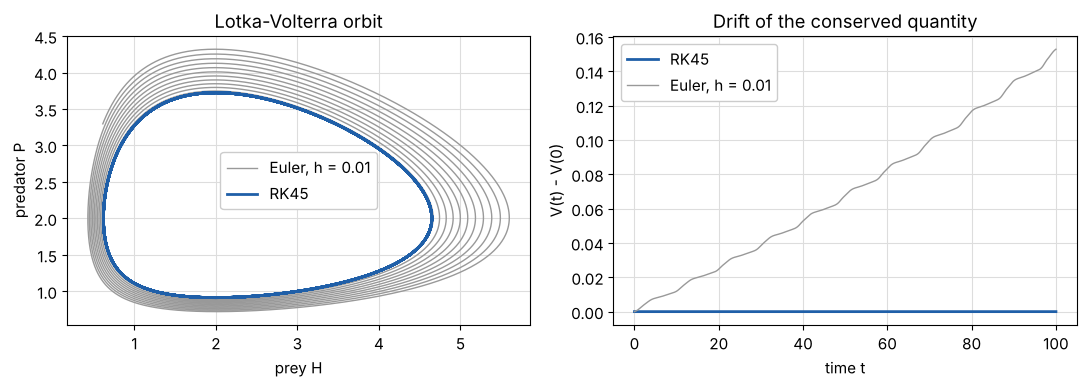

max |V - V0|: RK45 3.7e-10,  Euler 1.5e-01
relative change with 100x tighter tolerances: 8.1e-10
smallest state value at K = 150: 1.109  (> 0)


In [5]:
fig, check = solver_validation()
plt.show()

pF = with_K(BASE, 150.0)
t = np.linspace(0, 200, 8001)
a = integrate(pF, Y0, (0, 200), t_eval=t).y
b = integrate(pF, Y0, (0, 200), t_eval=t, rtol=1e-12, atol=1e-14).y
print(f"max |V - V0|: RK45 {check['max_drift_rk45']:.1e},  Euler {check['max_drift_euler']:.1e}")
print(f"relative change with 100x tighter tolerances: {np.abs(a - b).max() / np.abs(b).max():.1e}")
print(f"smallest state value at K = 150: {a.min():.3f}  (> 0)")

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figure 1</b>

RK45 keeps $V$ constant to about $10^{-10}$, so its orbit is closed as the theory requires. Euler's $V$ creeps up and its orbit
spirals outward, **inventing** behaviour the model does not have. Without an accurate solver we could not tell a real limit
cycle from a numerical artefact.

</div>

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">Step 2 &mdash; Reproducing Section 2's validation targets</b>

For each regime: eigenvalues of the Jacobian (at $E_1 = (K,0)$ for A, where $E^*$ is infeasible; at $E^*$ otherwise), then a
simulation from $(20,5)$ with a 3000-year burn-in and 400 recorded years.

</div>

In [6]:
rows = regime_table(BASE)
pd.DataFrame([{
    "regime": r["label"], "K": r["K"], "class": r["regime"],
    "eigenvalues": ", ".join(f"{z.real:+.3f}{z.imag:+.3f}i" for z in r["eig"]),
    "H range": f"[{r['Hmin']:.1f}, {r['Hmax']:.1f}]", "P range": f"[{r['Pmin']:.2f}, {r['Pmax']:.2f}]",
    "period (yr)": round(r["period"], 2), "lynx lag (yr)": round(r["lag"], 2)} for r in rows]).set_index("regime")

,K,class,eigenvalues,H range,P range,period (yr),lynx lag (yr)
regime,,,,,,,
A,25.0,predator_extinct,"-1.500+0.000i, -0.073+0.000i","[25.0, 25.0]","[0.00, 0.00]",NaN,NaN
B,60.0,stable_coexistence,"-0.188+0.515i, -0.188-0.515i","[30.0, 30.0]","[11.25, 11.25]",NaN,NaN
C,85.0,stable_coexistence,"-0.022+0.623i, -0.022-0.623i","[30.0, 30.0]","[14.56, 14.56]",NaN,NaN
D,90.0,hopf_point,"+0.000+0.632i, +0.000-0.632i","[28.5, 31.6]","[14.51, 15.49]",9.94,2.50
E,95.0,limit_cycle,"+0.020+0.640i, +0.020-0.640i","[15.8, 50.9]","[9.81, 20.75]",10.25,2.81
F,150.0,limit_cycle,"+0.150+0.676i, +0.150-0.676i","[1.1, 134.3]","[1.69, 41.16]",13.91,4.52


<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading the regime table</b>

Every row reproduces Joel's Table 2: A $\to (25,0)$; B and C settle on $(30, 11.25)$ and $(30, 14.56)$; E has
$H\in[15.8, 50.9]$, $T = 10.25$ yr; F has $H \in [1.1, 134.3]$, $T = 13.91$ yr. At **D** ($K = K_H$) a residual oscillation
of about $\pm 1.5$ remains after 3000 years: at the Hopf point decay is only algebraic ($\sim t^{-1/2}$), so this is a slow
transient, **not** a cycle. The lynx lag grows from about a quarter-period (2.5 yr) at onset to 4.5 yr at $K = 150$.

</div>

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">Step 3 &mdash; Time series and phase portraits (Figure 2)</b>

Regimes **B** (well below $K_H$), **C** (just below), **E** (just above), **F** (well above). Prey nullcline: the hump
$P = \frac{r}{a}(1-\frac{H}{K})(b+H)$ with peak at $H = \frac{K-b}{2}$; predator nullcline: the line $H = H^* = 30$.
Graphical criterion: $E^*$ is stable iff the vertical line meets the hump **right of its peak**.

</div>

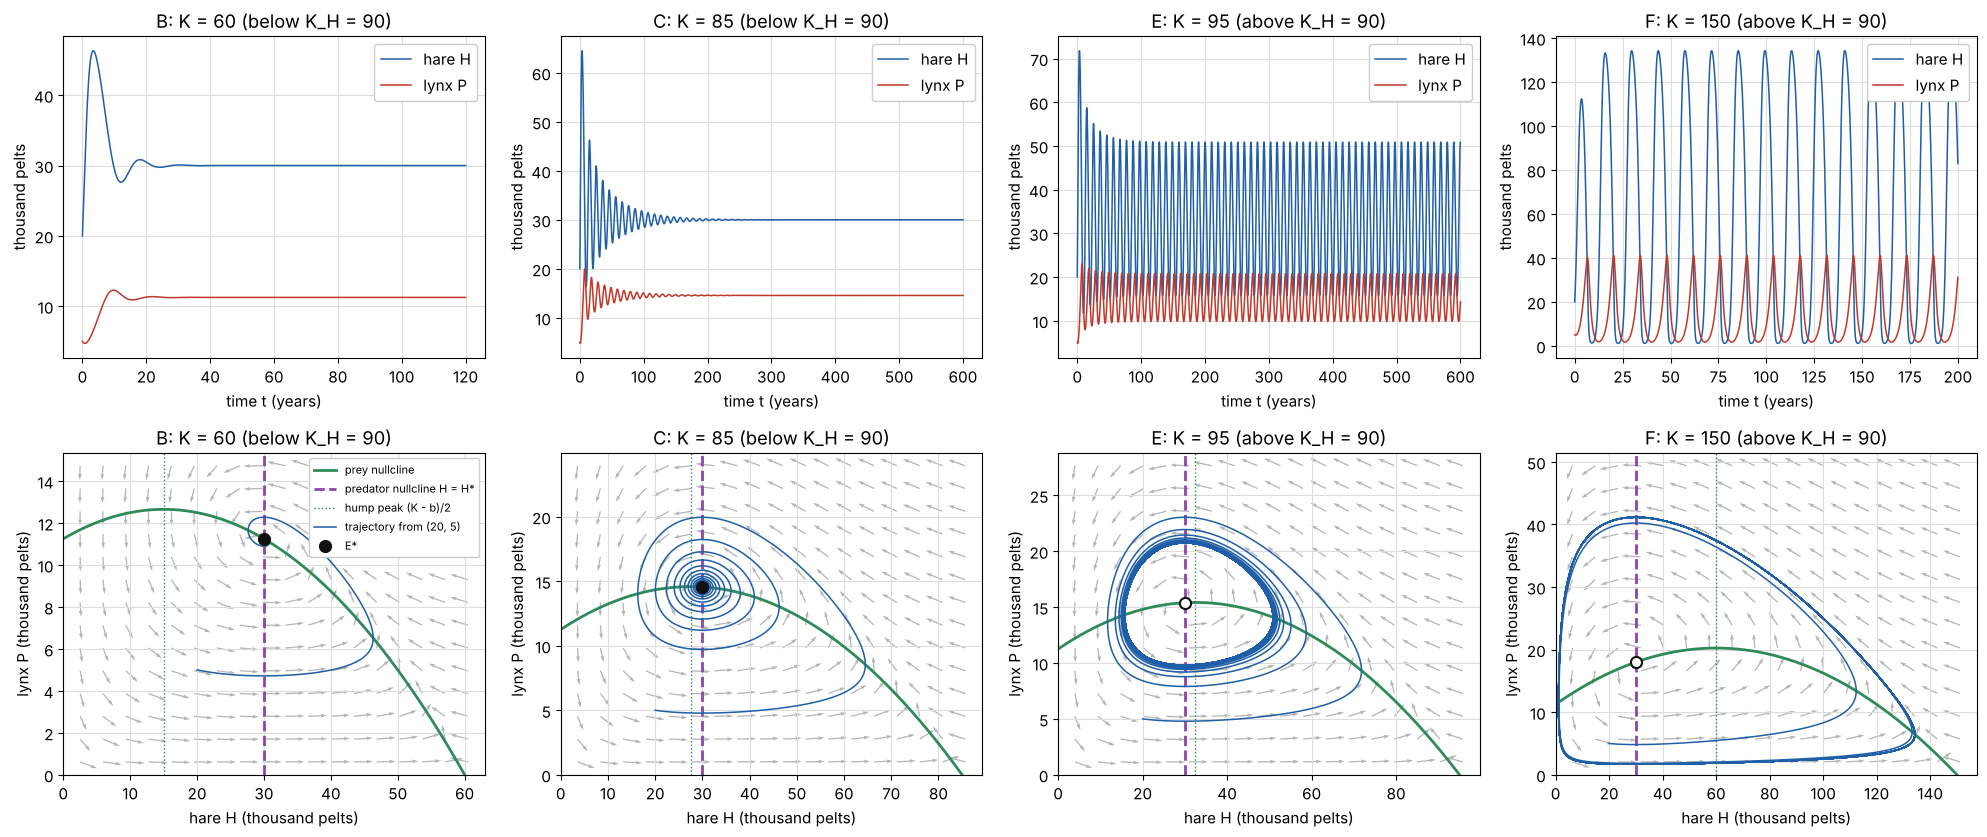

K =  60: trace = -0.3750, det = 0.3000  ->  stable_coexistence
K =  85: trace = -0.0441, det = 0.3882  ->  stable_coexistence
K =  95: trace = +0.0395, det = 0.4105  ->  limit_cycle
K = 150: trace = +0.3000, det = 0.4800  ->  limit_cycle


In [7]:
fig = regimes(BASE)
plt.show()
for K in (60, 85, 95, 150):
    p = with_K(BASE, K)
    tr, det = st.coexistence_trace_det(p)
    print(f"K = {K:3d}: trace = {tr:+.4f}, det = {det:.4f}  ->  {st.regime(p)}")

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figure 2</b>

- **B ($K=60$):** line right of the peak; oscillations die within a few decades and the orbit spirals into $E^*$.
- **C ($K=85$):** still right of the peak but barely; the trace is only $-0.044$, so decay takes centuries (e-fold about 45 yr).
- **E ($K=95$):** line just left of the peak; $E^*$ is unstable and the orbit settles on a cycle of period about 10 years.
- **F ($K=150$):** a large cycle; hares boom to 134 thousand and crash to about 1 thousand, lynx follow 4.5 years later.

The switch from decay to sustained cycling happens at $K_H = 90$, as Section 2 predicts. The flow is counter-clockwise.

</div>

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Step 4 &mdash; Is the cycle a stable limit cycle? (Figure 3)</b>

Lotka&ndash;Volterra has a different closed orbit for every start (neutral stability). A **stable limit cycle** is an isolated
orbit approached from both sides. At $K = 150$ we start inside (next to the unstable $E^*$) and outside, and track hare peaks.

</div>

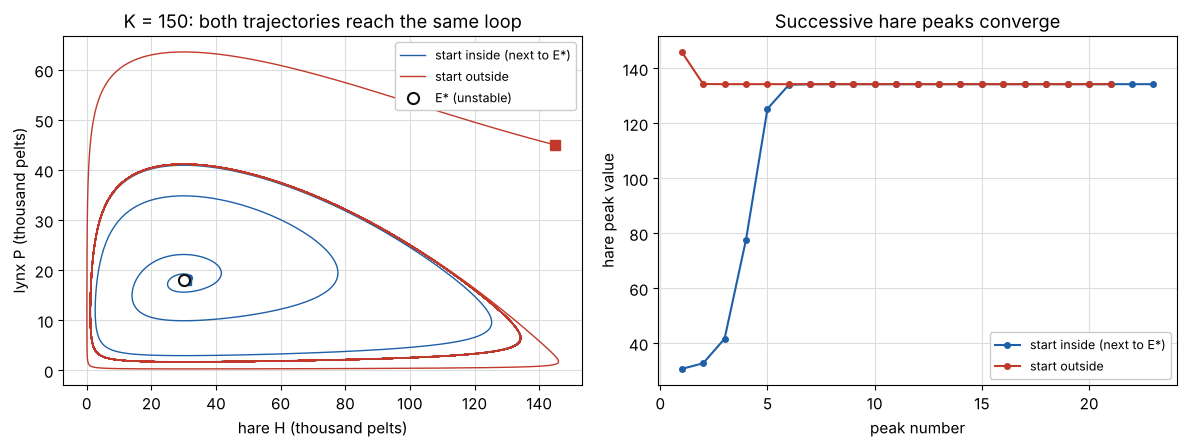

start inside (next to E*)    last three hare peaks: [134.277 134.277 134.277]
start outside                last three hare peaks: [134.277 134.277 134.277]


In [8]:
fig, last = limit_cycle_attracts(BASE)
plt.show()
for name, peaks in last.items():
    print(f"{name:28s} last three hare peaks: {np.round(peaks, 4)}")

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figure 3</b>

The inside orbit spirals **out**, the outside one spirals **in**, and both peak sequences converge to the same value (134.277).
So after a disturbance the populations return to the *same* cycle, the key improvement over Lotka&ndash;Volterra.
This is numerical evidence for one parameter set; the general statement is Cheng's uniqueness theorem cited in Section 2.

</div>

<div style="background:#e8f1fb; border-left:6px solid #1f5fa8; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1f5fa8; font-size:1.1em;">Step 5 &mdash; Eigenvalues of J(E*) versus K (Figure 4)</b>

$\det J^* > 0$ for every feasible $K$, so the real part of the eigenvalues has the sign of the trace. Prediction: it changes sign
at exactly $K_H = 90$ with $|\operatorname{Im}\lambda| = \omega_0 \approx 0.632$; below $K \approx 42.5$ the eigenvalues are real (node).

</div>

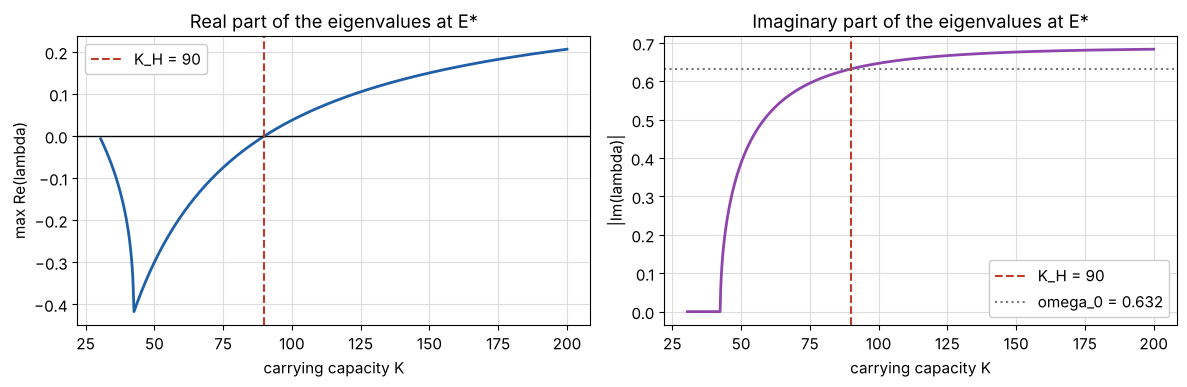

numerical trace zero: K = 90.0000000000   closed form K_H = 90.0000000000
node -> focus at K = 42.6


In [9]:
fig, info = eigenvalues_vs_K(BASE, np.linspace(30.5, 200, 800))
plt.show()
print(f"numerical trace zero: K = {hopf_crossing(BASE, 60, 120):.10f}   closed form K_H = {KH:.10f}")
print(f"node -> focus at K = {info['node_to_focus_K']:.1f}")

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figure 4</b>

$\operatorname{Re}\lambda$ is negative below 90, zero at 90 and positive above, crossing with nonzero slope (transversality);
$|\operatorname{Im}\lambda| = \omega_0$ at the crossing, so a **complex pair** crosses the imaginary axis: the Hopf condition.

</div>

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Step 6 &mdash; Numerical bifurcation diagram (Figure 5)</b>

**Algorithm:** for each $K$ on a grid from 32 to 200, start at $(20,5)$, integrate past the burn-in, **discard** the transient,
and record $\max$ and $\min$ of $H$ and $P$ over 300 further years. Equal max and min: an equilibrium. A gap: a cycle.

</div>

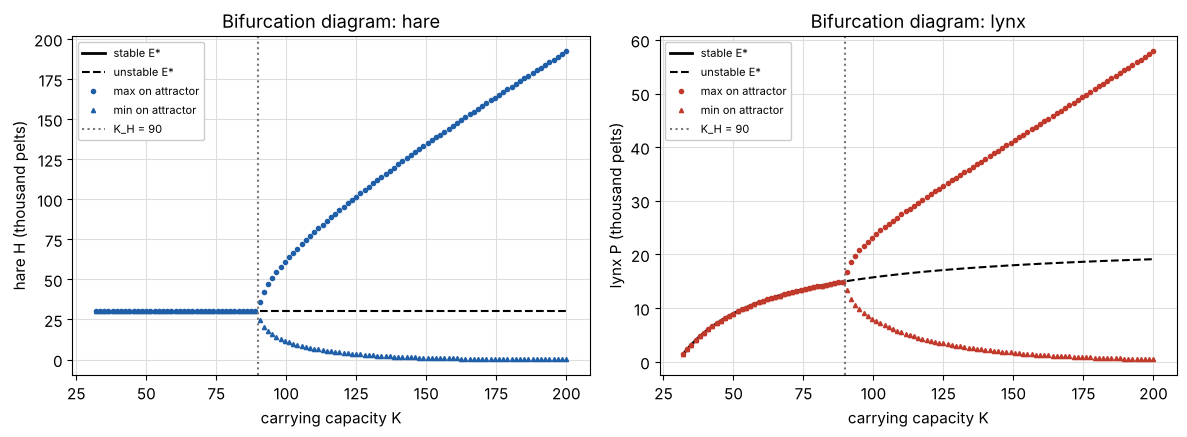

largest max-min of H for K < 89: 4.8e-05
cycle minimum at K = 200: H = 0.115, P = 0.454


In [10]:
sw = CONFIG["bifurcation_sweep"]
sweep = bifurcation_sweep(BASE, np.linspace(sw["K_min"], sw["K_max"], sw["points"]), t_record=sw["record_years"])
fig = bifurcation(BASE, sweep)
plt.show()
below = sweep["K"] < KH - 1
print(f"largest max-min of H for K < 89: {np.max(sweep['Hmax'][below] - sweep['Hmin'][below]):.1e}")
print(f"cycle minimum at K = 200: H = {sweep['Hmin'][-1]:.3f}, P = {sweep['Pmin'][-1]:.3f}")

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Step 7 &mdash; Amplitude law and period (Figure 6)</b>

A **supercritical** Hopf bifurcation predicts a cycle born with zero size whose half-amplitude grows like
$A \approx c\sqrt{K-K_H}$ (slope $\tfrac12$ on a log&ndash;log plot; Section 2: $c \approx 7.8$), and whose period tends to
$T_0 = 2\pi/\omega_0$ as $K \to K_H^+$. A subcritical one would instead jump to a large cycle.

</div>

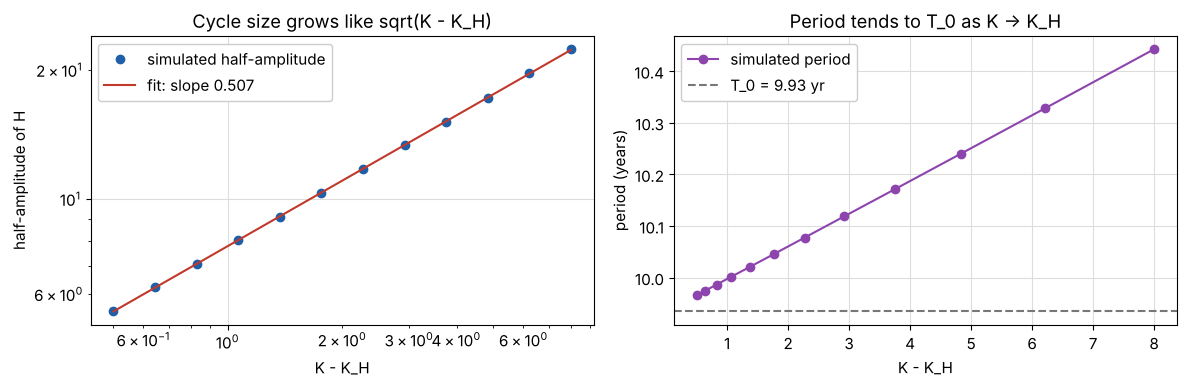

log-log slope s = 0.507  (prediction 0.5)
A = 7.81 * sqrt(K - K_H)  (Section 2: about 7.8)
period at K - K_H = 0.5: 9.966 yr  ->  T_0 = 9.935 yr


In [11]:
al = CONFIG["amplitude_law"]
law = amplitude_law(BASE, np.geomspace(al["dK_min"], al["dK_max"], al["points"]), t_record=al["record_years"])
fig = amplitude_and_period(law)
plt.show()
print(f"log-log slope s = {law['slope']:.3f}  (prediction 0.5)")
print(f"A = {law['coefficient_sqrt']:.2f} * sqrt(K - K_H)  (Section 2: about 7.8)")
print(f"period at K - K_H = 0.5: {law['period'][0]:.3f} yr  ->  T_0 = {law['onset_period']:.3f} yr")

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figures 5 and 6</b>

- **Below $K_H$** max and min coincide on the equilibrium: no cycle.
- **At $K_H$** the branches split and the cycle is born with **zero** size.
- **Above $K_H$** it grows continuously, with slope $\approx 0.507$: the $\sqrt{K-K_H}$ law of a **supercritical** Hopf bifurcation,
  consistent with Joel's computed $\ell_1 < 0$. The period starts at $T_0 \approx 9.94$ yr and lengthens with $K$.
- **Paradox of enrichment:** the minimum branches sink toward zero (hare minimum about 0.1 thousand at $K = 200$).
  The ODE never reaches zero, but a real, finite population at such troughs would risk extinction.

</div>

<div style="background:#fff3e3; border-left:6px solid #b8620a; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#b8620a; font-size:1.1em;">Step 8 &mdash; Where do the historical fits lie? (Figures 7 and 8)</b>

The fitting sections estimated all six coefficients from the 1900&ndash;1915 pelt indices (thousands of pelts) with a PINN
(13 runs: three error models &times; three seeds, wider bounds, physics weight 100) and matched least squares (18 starts).
For **every** saved parameter set we compute, with Joel's closed forms:

- the stability margin $\sigma = K/K_H$ ($\sigma < 1$: $E^*$ stable, oscillations damp; $\sigma > 1$: limit cycle);
- the eigenvalues $\mu \pm i\omega$ at $E^*$, the **e-folding time** $1/|\mu|$ and the **linear period** $2\pi/\omega$;
- the period and lynx lag of the first century simulated from the fitted 1900 state (Advay's check: about 10 yr, 1&ndash;2 yr);
- which coefficients sit within 0.5% of a box limit.

Only saved parameters and the training file are read; the test file is never opened. First we confirm the parameters are
read correctly: re-integrating Yash's selected fit with `model.solve` and the historical settings must reproduce his saved path.
The bifurcation sweeps take several minutes.

</div>

In [12]:
import runpy
placement = runpy.run_path(str(ROOT / "scripts" / "rishi_historical_placement.py"))
res = placement["compute"]()
print(f"model.solve reconstruction difference: {res['summary']['reconstruction_max_abs_difference']:.1e}")
cols = ["label", "sigma", "regime", "eigenvalue", "efold_years", "linear_period",
        "first_century_period", "first_century_lag", "cycle_H_range", "cycle_period", "parameters_on_bounds"]
display(pd.DataFrame([r for r in res["table"] if r["selected"]])[cols].set_index("label"))
for k, (lo, hi) in res["summary"]["sigma_range_by_group_excluding_poor_minima"].items():
    print(f"{k:38s} sigma in [{lo:.3f}, {hi:.3f}]")

model.solve reconstruction of Yash's selected PINN path: max abs difference 4.70e-12


model.solve reconstruction difference: 4.7e-12


,sigma,regime,eigenvalue,efold_years,linear_period,first_century_period,first_century_lag,cycle_H_range,cycle_period,parameters_on_bounds
label,,,,,,,,,,
PINN main,1.3631,limit_cycle,+0.0079+0.7122i,126.7,8.82,10.70,1.37,"[0.13, 247.1]",18.52,K=upper b=upper
PINN log errors,1.3425,limit_cycle,+0.0079+0.7665i,126.6,8.20,9.91,1.29,"[0.27, 240.1]",17.37,
PINN fitted initial state,1.3467,limit_cycle,+0.0070+0.6992i,143.4,8.99,10.71,1.42,"[0.18, 243.4]",19.37,b=upper
"PINN main, wider bounds",1.4800,limit_cycle,+0.0049+0.7090i,204.4,8.86,10.49,1.34,"[0.00, 514.7]",33.29,b=upper
"PINN main, physics weight 100",1.3636,limit_cycle,+0.0091+0.6871i,110.5,9.14,11.28,1.42,"[0.18, 210.0]",17.59,
Least squares main,1.0672,limit_cycle,+0.0018+0.6834i,554.2,9.19,10.37,1.57,"[5.57, 85.0]",10.77,a=upper b=upper
Least squares log errors,0.5497,stable_coexistence,-0.0190+0.6804i,52.7,9.23,9.41,2.04,,,b=upper
Least squares fitted initial state,0.9930,stable_coexistence,-0.0002+0.6694i,5599.5,9.39,10.34,1.66,,,b=upper


PINN main                              sigma in [1.360, 1.366]
PINN log errors                        sigma in [1.342, 1.354]
PINN fitted initial state              sigma in [1.323, 1.348]
PINN main, wider bounds                sigma in [1.466, 1.481]
PINN main, physics weight 100          sigma in [1.364, 1.364]
Least squares main                     sigma in [1.067, 1.067]
Least squares log errors               sigma in [0.550, 0.550]
Least squares fitted initial state     sigma in [0.993, 0.993]


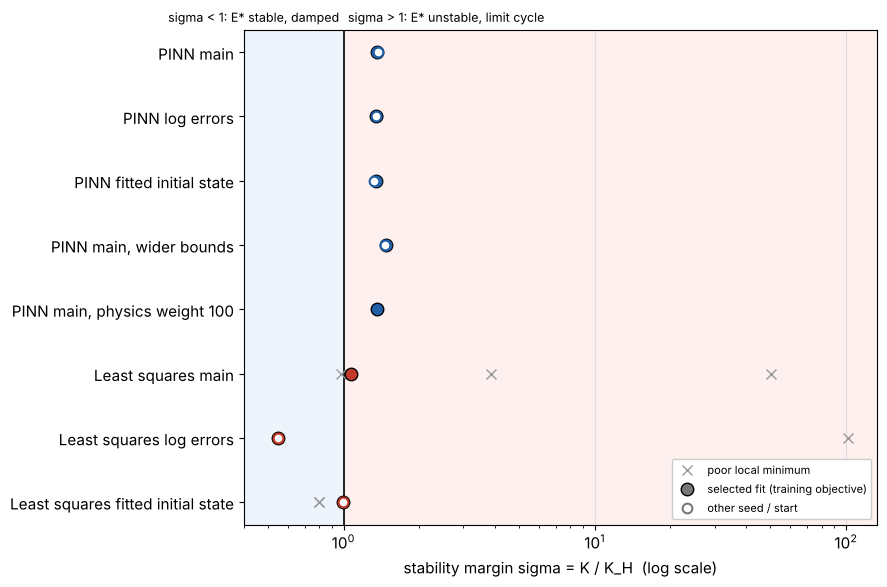

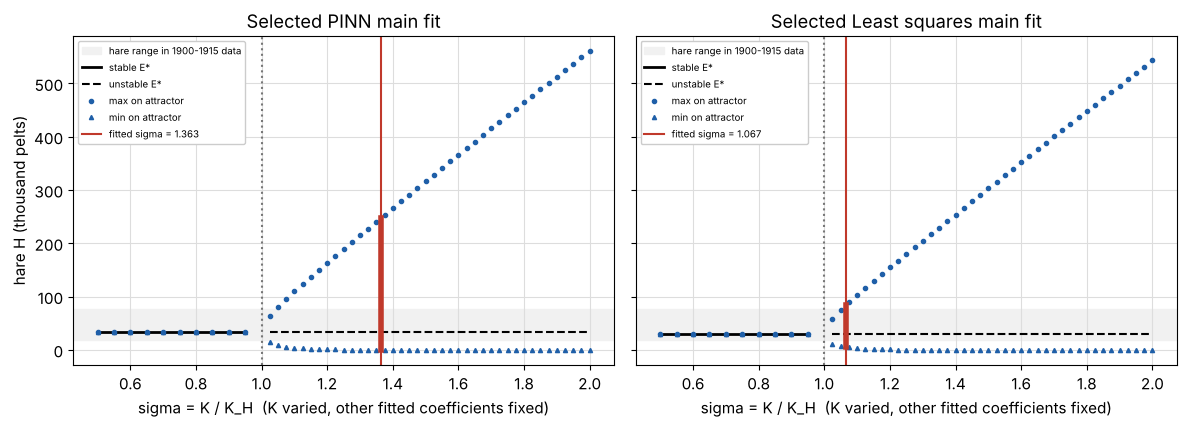

In [13]:
fig_sigma, fig_bif = placement["figures"](res)
display(fig_sigma, fig_bif)
plt.close("all")

<div style="background:#e9f7ee; border-left:6px solid #1e7a45; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#1e7a45; font-size:1.1em;">Reading Figures 7 and 8</b>

- **Same behaviour over the data window.** Every well-fitting set oscillates with a period of about 10 years and a lynx lag of
  1.3&ndash;2 years, matching the data.
- **Different side of the threshold.** PINN fits give $\sigma \approx 1.32$&ndash;$1.48$; least squares gives 1.07 (main),
  0.99 (fitted initial state) and 0.55 (log errors).
- **Why the data cannot decide.** $|\mu|$ is only 0.0002&ndash;0.019 per year, so the e-folding time is 53&ndash;5600 years.
  Over 16 training years oscillations change by a factor $e^{16\mu} \approx 0.74$&ndash;$1.16$: a slowly damped focus and a slowly
  growing spiral give almost the same two cycles.
- **Bounds matter.** $b$ sits on its upper limit in nearly every fit; widening the box moves the PINN's $\sigma$ from 1.36 to 1.48.
- **Long run (Figure 8).** The least-squares fit's eventual cycle ($H$ 5.6&ndash;85, period 10.8 yr) resembles the data; the PINN
  fit's is much larger ($H$ 0.1&ndash;247, period 18.5 yr), so its 1900&ndash;1920 trajectory is an early part of a slowly growing spiral.

**Conclusion:** the fitted model sits close to the Hopf threshold and reproduces the observed period and lag, but these data do
not establish whether the real system is on a stable limit cycle or a slowly damped oscillation.

</div>

<div style="background:#f2ecfa; border-left:6px solid #6a3ea1; padding:12px 16px; border-radius:6px; color:#1a1a1a;">

<b style="color:#6a3ea1; font-size:1.1em;">Summary and handoff</b>

| Claim | Numerical evidence | Where |
|---|---|---|
| Solver accurate | LV invariant kept to $10^{-10}$ (Euler drifts 0.15); tolerance change $10^{-9}$; positivity | Fig. 1 |
| Section 2 targets | All six regimes, eigenvalues, periods and lags reproduced | table |
| Stability switch at $K_H$ | Decay at $K = 60, 85$; cycles at $K = 95, 150$ | Fig. 2 |
| Stable limit cycle | Inside and outside starts reach the same loop | Fig. 3 |
| Hopf at $K_H = b + 2H^*$ | Trace zero at $K = 90.0000000000$, $|\operatorname{Im}\lambda| = \omega_0$ | Fig. 4 |
| Supercritical Hopf; enrichment | Amplitude $\propto (K-K_H)^{0.507}$, period $\to T_0$, troughs $\to 0$ | Figs. 5, 6 |
| Historical fits | Period ~10 yr, lag 1.3&ndash;2 yr for every good fit; $\sigma$ 0.55&ndash;1.48 depending on method, error model and bounds | Figs. 7, 8 |

**Solvers:** fitting and 1900&ndash;1920 forecasts use `model.solve` (rtol 1e-8, atol 1e-10, max_step 0.1); long-run runs here use
`simulation.integrate` (rtol 1e-10, atol 1e-12).

**Limitations:** the illustrative runs use unfitted parameters; simulation is evidence, not proof; near $K_H$ results depend on
burn-in length; fitted $\sigma$ depends on the box bounds and the error model.

</div>